# Muse Spark Open — reasoning-effort sweep

Same short-answer suite as the Muse vs DeepSeek demo, but **Muse only**, sweeping the full effort ladder:

`minimal` → `low` → `medium` → `high` → `xhigh` → `max`

| Answer type | Bench |
|---|---|
| number | GSM8K |
| yes/no | BoolQ |
| string | NQ-Open |
| choice | ARC-Easy |

Point for the Meta demo: **more effort is not always better** on these easy short-answer tasks (Muse often peaks at `low`).

Resumable into shared `results.jsonl`. `RUN_SWEEP = True` by default.


## Setup


In [1]:
# Run once if imports fail.
import sys
!{sys.executable} -m pip install -q openai datasets python-dotenv matplotlib pandas numpy tqdm


In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

HERE = Path.cwd()
if not (HERE / "run_simple_bench.py").exists():
    HERE = Path("experiments/meta-hackathon-muse")
RESULTS = HERE / "results.jsonl"

repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / ".env").exists() or (p / "requirements.txt").exists()),
    Path.cwd(),
)
load_dotenv(repo_root / ".env")

RUN_SWEEP = True
N_PER_BENCH = 100
EFFORTS = ["minimal", "low", "medium", "high", "xhigh", "max"]  # Muse rejects "none"
MUSE = "Muse Spark Open"
MUSE_C = "#0B6E4F"
EFFORT_COLORS = {
    "minimal": "#05402E",
    "low": "#0B6E4F",
    "medium": "#2A9D6A",
    "high": "#5BBF8A",
    "xhigh": "#A8D5C0",
    "max": "#D3EBE0",
}

print("results:", RESULTS, "exists=", RESULTS.exists())
print("FIREWORKS_API_KEY set:", bool(os.getenv("FIREWORKS_API_KEY")))
print(f"RUN_SWEEP={RUN_SWEEP}  N_PER_BENCH={N_PER_BENCH}  EFFORTS={EFFORTS}")


results: /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl exists= True
FIREWORKS_API_KEY set: True
RUN_SWEEP=True  N_PER_BENCH=100  EFFORTS=['minimal', 'low', 'medium', 'high', 'xhigh', 'max']


## Run Muse effort sweep

Fills any missing `(Muse, effort, id)` rows. Reuses existing `low` / partial `high` cache.


In [3]:
if RUN_SWEEP:
    import run_simple_bench as bench
    # Jupyter has a running loop — await, don't asyncio.run()
    await bench.run(EFFORTS, N_PER_BENCH, ["muse"])
    print("sweep done →", RESULTS)
else:
    print("using cached results only")


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rows=400 pending=0 results=/Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl
nothing to run
sweep done → /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/results.jsonl


## Scoreboard: pass@1 by answer type × effort


In [4]:
rows = [json.loads(l) for l in RESULTS.open() if l.strip()]
df = pd.DataFrame(rows)
df = df[(df["model"] == MUSE) & (df["effort"].isin(EFFORTS))].copy()
assert not df.empty, f"No Muse rows in {RESULTS}"

piv = (df.pivot_table(index="bench", columns="effort", values="score", aggfunc="mean") * 100).round(1)
order_b = ["gsm8k", "boolq", "nq_open", "arc_easy"]
piv = piv.reindex([b for b in order_b if b in piv.index])
piv = piv[[e for e in EFFORTS if e in piv.columns]]
piv.index = piv.index.map({
    "gsm8k": "number (GSM8K)",
    "boolq": "yes/no (BoolQ)",
    "nq_open": "string (NQ-Open)",
    "arc_easy": "choice (ARC-Easy)",
})

counts = df.groupby(["bench", "effort"]).size().unstack()
print(f"pass@1 (%) — Muse Spark Open  |  samples/cell:")
display(counts.reindex(order_b)[[e for e in EFFORTS if e in counts.columns]])
print()
display(piv)

overall = (df.groupby("effort")["score"].mean() * 100).reindex(EFFORTS)
print("\noverall pass@1 by effort:")
for e, v in overall.items():
    marker = " ← best" if v == overall.max() else ""
    print(f"  {e:7} {v:5.1f}%{marker}")
best = overall.idxmax()
print(f"\npeak effort: {best} ({overall[best]:.1f}%)")


pass@1 (%) — Muse Spark Open  |  samples/cell:


effort,minimal,low,medium,high,xhigh,max
bench,,,,,,
gsm8k,100,100,100,100,100,100
boolq,100,100,100,100,100,100
nq_open,100,100,100,100,100,100
arc_easy,100,100,100,100,100,100


effort,minimal,low,medium,high,xhigh,max
bench,,,,,,
number (GSM8K),98.0,99.0,99.0,94.0,98.0,97.0
yes/no (BoolQ),93.0,90.0,93.0,86.0,89.0,84.0
string (NQ-Open),64.0,69.0,67.0,64.0,66.0,65.0
choice (ARC-Easy),95.0,96.0,92.0,83.0,85.0,86.0



overall pass@1 by effort:
  minimal  87.5%
  low      88.5% ← best
  medium   87.8%
  high     81.8%
  xhigh    84.5%
  max      83.0%

peak effort: low (88.5%)


## Chart: pass@1 vs reasoning effort


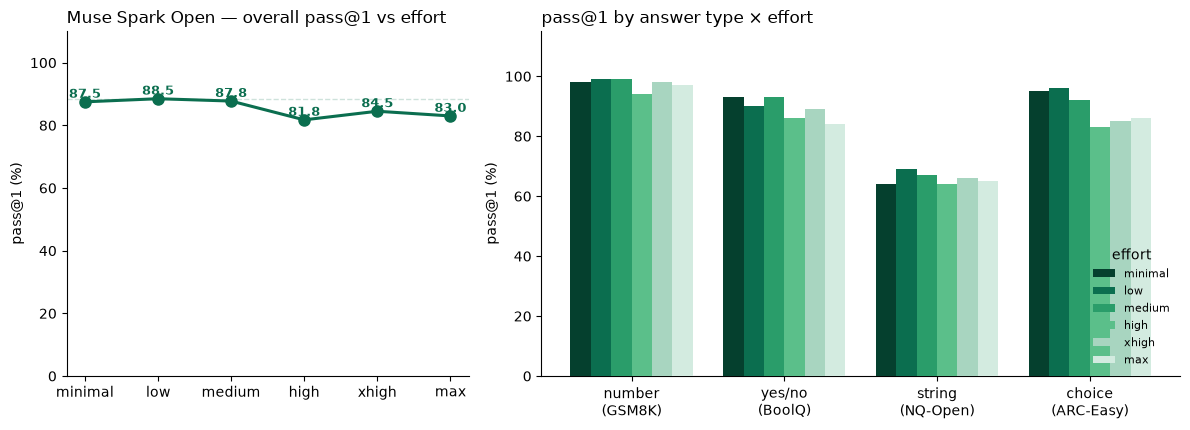

saved /Users/sinan/ai-experiments/experiments/meta-hackathon-muse/muse_effort_sweep.png


In [5]:
# Left: overall pass@1 vs effort. Right: by answer type.
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [0.85, 1.35]})

# --- overall ---
xs = np.arange(len(EFFORTS))
vals = [overall.get(e, np.nan) for e in EFFORTS]
ax.plot(xs, vals, "-o", color=MUSE_C, lw=2.2, markersize=8, zorder=3)
for i, (e, v) in enumerate(zip(EFFORTS, vals)):
    if np.isfinite(v):
        ax.text(i, v + 1.3, f"{v:.1f}", ha="center", fontsize=9, fontweight="bold", color=MUSE_C)
ax.set_xticks(xs)
ax.set_xticklabels(EFFORTS)
ax.set_ylim(0, 110)
ax.set_ylabel("pass@1 (%)")
ax.set_title("Muse Spark Open — overall pass@1 vs effort", loc="left")
ax.axhline(overall.max(), color="#0B6E4F33", ls="--", lw=1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# --- by answer type (grouped bars) ---
benches = [b for b in order_b if b in df["bench"].unique()]
labels = {
    "gsm8k": "number\n(GSM8K)",
    "boolq": "yes/no\n(BoolQ)",
    "nq_open": "string\n(NQ-Open)",
    "arc_easy": "choice\n(ARC-Easy)",
}
g = df.groupby(["bench", "effort"])["score"].mean() * 100
x = np.arange(len(benches))
w = 0.8 / max(1, len(EFFORTS))
for i, e in enumerate(EFFORTS):
    ys = [g.get((b, e), np.nan) for b in benches]
    ax2.bar(x + i * w - 0.4 + w / 2, ys, width=w, label=e, color=EFFORT_COLORS.get(e, MUSE_C), zorder=3)

ax2.set_xticks(x)
ax2.set_xticklabels([labels[b] for b in benches])
ax2.set_ylim(0, 115)
ax2.set_ylabel("pass@1 (%)")
ax2.set_title("pass@1 by answer type × effort", loc="left")
ax2.legend(frameon=False, title="effort", loc="lower right", fontsize=8)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

fig.tight_layout()
out = HERE / "muse_effort_sweep.png"
fig.savefig(out, dpi=160, bbox_inches="tight")
plt.show()
print("saved", out)


## Talking point

On these **easy short-answer** tasks, Muse peaks at **`low`**, with `minimal` and `medium` close behind. Cranking to `high` / `xhigh` / `max` burns tokens and lowers pass@1. Part of the `max` drop is truncation: 19 of 400 `max` answers were empty because reasoning used up the 2,048-token output limit.

Pair with the Muse-vs-DeepSeek notebook: Muse @ `low` beats DeepSeek, *and* Muse doesn’t need max effort to get there.
